# **Notebook 6: Fine-Tuning Pipeline**
## Assignment: Hybrid RAG & Fine-Tuning for Customer Support
---

### TO-DO: Before Running This Notebook

**Files you NEED:**
- [ ] `./tokenized_train/` + `./tokenized_valid/` — Created by Notebook 2
- [ ] GPU runtime enabled (T4 minimum)

**Files this notebook will CREATE:**
- [ ] `./intent_lora_best/` — Best LoRA checkpoint (by val loss) _(Required by NB7)_
- [ ] `./intent_lora/` — Final LoRA checkpoint _(Backup)_
- [ ] `training_log.csv` + `training_curves.png` — Evidence for report

---

## **Stage 4: Solution V2 (Fine-Tuned Retrieval-Assisted Generation)**

### **Task 4.1: Configure Fine-Tuning Pipeline**

#### **4.1.1 Configure PEFT Framework [3 marks]**
**The Task:** Apply LoRA (or QLoRA) to the model's `q_proj` and `v_proj` attention modules, set adapter settings and target modules, and prepare the training environment.

**Hints & Tips:**
* LoRA adds small trainable matrices to frozen attention layers — only ~0.5–1% of params update.
* `r=16` = rank of the low-rank matrices; `lora_alpha=32` scales them (rule of thumb: alpha = 2×r).
* `target_modules=["q_proj","v_proj"]`. Adding `["k_proj","o_proj"]` trains more params but may overfit on small data.
* Call `peft_model.print_trainable_parameters()` to confirm the tiny trainable %.

**LoRA Config Tuning:**
* `r`: 8 (lighter), **16 (recommended)**, 32 (more capacity).
* `lora_alpha`: usually 2×r → 16, **32**, 64.

**Learner Inference:** Updating only attention projections fundamentally changes behaviour (chat → JSON) using a fraction of the compute.

In [8]:
!pip install -U "bitsandbytes>=0.46.1" accelerate transformers
!pip install -q -U peft

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 187.2 MB/s eta 0:00:00
  Attempting uninstall: transformers
    Found existing installation: transformers 5.17.0
    Uninstalling transformers-5.17.0:
      Successfully uninstalled transformers-5.17.0


In [1]:
# YOUR CODE HERE
# ============================================================
# Configure PEFT / LoRA
# ============================================================



import torch
from peft import LoraConfig, get_peft_model, TaskType

import torch
from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM,
    BitsAndBytesConfig
)

MODEL_NAME = "Qwen/Qwen2.5-1.5B-Instruct"

bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_use_double_quant=True
)

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    quantization_config=bnb_config,
    device_map="auto"
)

model.eval()

print("Model loaded successfully.")

# LoRA configuration
lora_config = LoraConfig(
    r=16,
    lora_alpha=32,
    target_modules=["q_proj", "v_proj"],
    lora_dropout=0.05,
    bias="none",
    task_type=TaskType.CAUSAL_LM
)

# Attach LoRA adapters to the quantized Qwen model
peft_model = get_peft_model(model, lora_config)

# Verify trainable parameters
peft_model.print_trainable_parameters()

for name, module in peft_model.named_modules():
    if "lora_" in name and ("q_proj" in name or "v_proj" in name):
        print(name)

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Model loaded successfully.
trainable params: 2,179,072 || all params: 1,545,893,376 || trainable%: 0.1410
base_model.model.model.layers.0.self_attn.q_proj.lora_dropout
base_model.model.model.layers.0.self_attn.q_proj.lora_dropout.default
base_model.model.model.layers.0.self_attn.q_proj.lora_A
base_model.model.model.layers.0.self_attn.q_proj.lora_A.default
base_model.model.model.layers.0.self_attn.q_proj.lora_B
base_model.model.model.layers.0.self_attn.q_proj.lora_B.default
base_model.model.model.layers.0.self_attn.q_proj.lora_embedding_A
base_model.model.model.layers.0.self_attn.q_proj.lora_embedding_B
base_model.model.model.layers.0.self_attn.q_proj.lora_magnitude_vector
base_model.model.model.layers.0.self_attn.v_proj.lora_dropout
base_model.model.model.layers.0.self_attn.v_proj.lora_dropout.default
base_model.model.model.layers.0.self_attn.v_proj.lora_A
base_model.model.model.layers.0.self_attn.v_proj.lora_A.default
base_model.model.model.layers.0.self_attn.v_proj.lora_B
base_model.

#### **4.1.2 Configure Training Parameters [2 marks]**
**The Task:** Define the learning rate, batch size, number of steps/epochs, optimisation strategy (AdamW), and quantisation settings.

**Hints & Tips:**
* Initialise `AdamW(filter(lambda p: p.requires_grad, peft_model.parameters()), lr=2e-4)`.
* Build `DataLoader`s for the train and validation sets (remember `set_format("torch", ...)` after `load_from_disk`).
* Define `VAL_EVERY` (e.g. 10 steps) and an early-stopping `PATIENCE` (e.g. 3) for the next task.

**Parameter Tuning:**
* `lr=2e-4` standard; try `1e-4` (slower) or `5e-4` (faster).
* `batch_size=4` fits T4; use 2 if OOM, 8 on A100.
* `max_steps=200`: ~25% of one epoch on 3200 rows. Increase to 400–500 for a full epoch.

**Learner Inference:** These hyperparameters control how fast and how stably the adapter learns the JSON-extraction task.

In [5]:
# YOUR CODE HERE
from torch.utils.data import DataLoader
from google.colab import drive
import pandas as pd
from datasets import Dataset

drive.mount('/content/drive')

train_dataset = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/HYBRID-RAG-AND-FINE-TUNING-ASSIGNMENT/OUPUT/train_data.csv')
train_dataset.head()

val_dataset = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/HYBRID-RAG-AND-FINE-TUNING-ASSIGNMENT/OUPUT/validation_data.csv')
val_dataset.head()

train_dataset = Dataset.from_pandas(train_dataset)
val_dataset = Dataset.from_pandas(val_dataset)


# QLoRA / 4-bit quantization settings
print(bnb_config)

# Training hyperparameters

LEARNING_RATE = 2e-4
BATCH_SIZE = 4
MAX_STEPS = 200

VAL_EVERY = 10
PATIENCE = 3

print("Learning rate:", LEARNING_RATE)
print("Batch size:", BATCH_SIZE)
print("Max steps:", MAX_STEPS)
print("Validation every:", VAL_EVERY, "steps")
print("Early stopping patience:", PATIENCE)

# Convert Hugging Face datasets to PyTorch format
train_dataset.set_format(
    type="torch",
    columns=["instruction", "intent", "category", "text"]
)

val_dataset.set_format(
    type="torch",
    columns=["instruction", "intent", "category", "text"]
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

from torch.optim import AdamW

optimizer = AdamW(
    filter(lambda p: p.requires_grad, peft_model.parameters()),
    lr=LEARNING_RATE
)

print("Optimizer:", optimizer)

trainable_params = [
    p for p in peft_model.parameters()
    if p.requires_grad
]

print(
    "Trainable parameters:",
    sum(p.numel() for p in trainable_params)
)

print("===== Training Configuration =====")
print(f"Learning rate : {LEARNING_RATE}")
print(f"Batch size    : {BATCH_SIZE}")
print(f"Max steps     : {MAX_STEPS}")
print(f"Validation    : Every {VAL_EVERY} steps")
print(f"Patience      : {PATIENCE}")
print("Optimizer     : AdamW")
print("Quantization  : 4-bit NF4")
print("LoRA targets  : q_proj, v_proj")
print("=================================")

peft_model.print_trainable_parameters()



Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
BitsAndBytesConfig {
  "_load_in_4bit": true,
  "_load_in_8bit": false,
  "bnb_4bit_compute_dtype": "float16",
  "bnb_4bit_quant_storage": "uint8",
  "bnb_4bit_quant_type": "nf4",
  "bnb_4bit_use_double_quant": true,
  "llm_int8_enable_fp32_cpu_offload": false,
  "llm_int8_has_fp16_weight": false,
  "llm_int8_skip_modules": null,
  "llm_int8_threshold": 6.0,
  "load_in_4bit": true,
  "load_in_8bit": false,
  "quant_method": "bitsandbytes"
}

Learning rate: 0.0002
Batch size: 4
Max steps: 200
Validation every: 10 steps
Early stopping patience: 3
Training batches: 781
Validation batches: 98
Optimizer: AdamW (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: True
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.0002
    maximize: False
    weight_decay: 0.01
)
Train

### **Task 4.2: Train Fine-Tuned Model**

#### **4.2.1 Execute Fine-Tuning [5 marks]**
**The Task:** Run the custom PyTorch training loop. Monitor BOTH train and validation loss at regular intervals, implement early stopping based on validation loss, and plot the train-vs-validation loss curves.

**Hints & Tips:**
* The validation loop runs every `VAL_EVERY` steps under `torch.no_grad()` (no gradients).
* Early stopping: track `best_val_loss`; if it doesn't improve for `PATIENCE` checks, stop.
* The loss-curve plot is mandatory evidence — save it as `training_curves.png`.

**What to look for in the curve:**
* Both lines falling → learning, no overfitting.
* Val rises while train falls → overfitting (early stopping saves you).
* Both flat → LR too low or data too small.
* Val spikes → bad batch / instability.

**Learner Inference:** Falling loss proves gradient descent is teaching the JSON format. Validation monitoring prevents silent memorisation.

In [6]:
# YOUR CODE HERE
import torch
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# ---------------------------------------------------------
# Configuration
# ---------------------------------------------------------
LEARNING_RATE = 2e-4
BATCH_SIZE = 4
MAX_STEPS = 200

VAL_EVERY = 10
PATIENCE = 3
MAX_LENGTH = 128

# ---------------------------------------------------------
# IMPORTANT:
# Keep datasets as text. Do NOT use set_format(type="torch")
# on the text columns.
# ---------------------------------------------------------

train_dataset.reset_format()
val_dataset.reset_format()

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

# ---------------------------------------------------------
# Tokenization helper
# ---------------------------------------------------------
def tokenize_batch(batch):
    tokens = tokenizer(
        batch["text"],
        padding=True,
        truncation=True,
        max_length=MAX_LENGTH,
        return_tensors="pt"
    )

    input_ids = tokens["input_ids"]
    attention_mask = tokens["attention_mask"]

    # Causal LM labels
    labels = input_ids.clone()

    # Ignore padding tokens when calculating loss
    labels[attention_mask == 0] = -100

    return {
        "input_ids": input_ids,
        "attention_mask": attention_mask,
        "labels": labels
    }


# ---------------------------------------------------------
# Optimizer
# ---------------------------------------------------------
optimizer = AdamW(
    filter(lambda p: p.requires_grad, peft_model.parameters()),
    lr=LEARNING_RATE
)

# ---------------------------------------------------------
# Training
# ---------------------------------------------------------
peft_model.train()

train_losses = []
val_losses = []

global_step = 0
best_val_loss = float("inf")
patience_counter = 0

train_iterator = iter(train_loader)

print("\n===== Starting Training =====")

progress_bar = tqdm(total=MAX_STEPS, desc="Training")

while global_step < MAX_STEPS:

    # Restart dataloader when one epoch finishes
    try:
        batch = next(train_iterator)
    except StopIteration:
        train_iterator = iter(train_loader)
        batch = next(train_iterator)

    # Tokenize batch
    inputs = tokenize_batch(batch)

    inputs = {
        key: value.to(device)
        for key, value in inputs.items()
    }

    # -----------------------------------------------------
    # Training step
    # -----------------------------------------------------
    peft_model.train()

    optimizer.zero_grad()

    outputs = peft_model(**inputs)

    loss = outputs.loss

    loss.backward()

    optimizer.step()

    global_step += 1

    train_loss = loss.item()
    train_losses.append(train_loss)

    progress_bar.update(1)
    progress_bar.set_postfix(
        train_loss=f"{train_loss:.4f}"
    )

    # -----------------------------------------------------
    # Validation
    # -----------------------------------------------------
    if global_step % VAL_EVERY == 0:

        peft_model.eval()

        validation_loss = 0.0
        validation_batches = 0

        with torch.no_grad():

            for val_batch in val_loader:

                val_inputs = tokenize_batch(val_batch)

                val_inputs = {
                    key: value.to(device)
                    for key, value in val_inputs.items()
                }

                val_outputs = peft_model(**val_inputs)

                validation_loss += val_outputs.loss.item()
                validation_batches += 1

        avg_val_loss = validation_loss / validation_batches

        val_losses.append(
            (global_step, avg_val_loss)
        )

        print(
            f"\nStep {global_step:3d} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {avg_val_loss:.4f}"
        )

        # -------------------------------------------------
        # Early stopping
        # -------------------------------------------------
        if avg_val_loss < best_val_loss:

            best_val_loss = avg_val_loss
            patience_counter = 0

            print(
                f"  ✓ Validation loss improved "
                f"to {best_val_loss:.4f}"
            )

            # Save best LoRA adapter
            peft_model.save_pretrained(
                "./best_peft_model"
            )

        else:

            patience_counter += 1

            print(
                f"  No improvement "
                f"({patience_counter}/{PATIENCE})"
            )

            if patience_counter >= PATIENCE:

                print(
                    f"\nEarly stopping triggered at "
                    f"step {global_step}."
                )

                break

progress_bar.close()

print("\n===== Training Complete =====")
print("Steps completed:", global_step)
print("Best validation loss:", best_val_loss)

Device: cuda
Training batches: 781
Validation batches: 98

===== Starting Training =====


Training:   0%|          | 0/200 [00:00<?, ?it/s]


Step  10 | Train Loss: 2.9279 | Val Loss: 2.7645
  ✓ Validation loss improved to 2.7645

Step  20 | Train Loss: 1.6909 | Val Loss: 1.5964
  ✓ Validation loss improved to 1.5964

Step  30 | Train Loss: 1.0175 | Val Loss: 1.1417
  ✓ Validation loss improved to 1.1417

Step  40 | Train Loss: 1.0960 | Val Loss: 1.0537
  ✓ Validation loss improved to 1.0537

Step  50 | Train Loss: 1.0874 | Val Loss: 0.9882
  ✓ Validation loss improved to 0.9882

Step  60 | Train Loss: 0.8410 | Val Loss: 0.9359
  ✓ Validation loss improved to 0.9359

Step  70 | Train Loss: 0.8265 | Val Loss: 0.8832
  ✓ Validation loss improved to 0.8832

Step  80 | Train Loss: 0.8172 | Val Loss: 0.8261
  ✓ Validation loss improved to 0.8261

Step  90 | Train Loss: 0.7736 | Val Loss: 0.7450
  ✓ Validation loss improved to 0.7450

Step 100 | Train Loss: 0.6521 | Val Loss: 0.6732
  ✓ Validation loss improved to 0.6732

Step 110 | Train Loss: 0.5883 | Val Loss: 0.6309
  ✓ Validation loss improved to 0.6309

Step 120 | Train Los

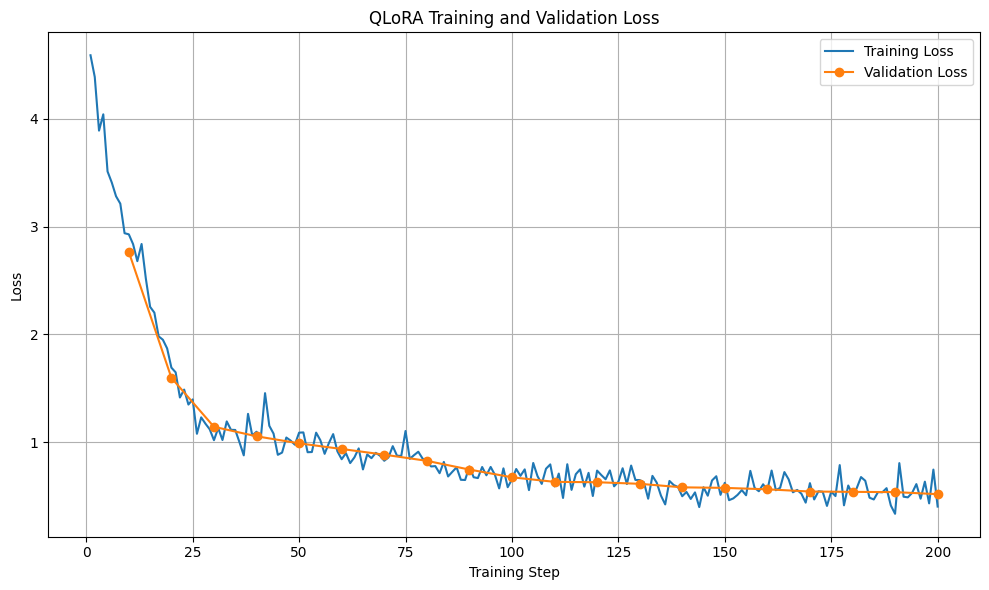

Saved: training_curves.png
training_curves.png exists: True
Best validation loss: 0.5167660923028479
Final training loss: 0.4013994336128235


In [7]:
# YOUR CODE HERE
# ---------------------------------------------------------
# Prepare validation points
# ---------------------------------------------------------
val_steps = [step for step, loss in val_losses]
val_loss_values = [loss for step, loss in val_losses]

train_steps = range(1, len(train_losses) + 1)

# ---------------------------------------------------------
# Plot
# ---------------------------------------------------------
plt.figure(figsize=(10, 6))

plt.plot(
    train_steps,
    train_losses,
    label="Training Loss"
)

plt.plot(
    val_steps,
    val_loss_values,
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Training Step")
plt.ylabel("Loss")
plt.title("QLoRA Training and Validation Loss")

plt.legend()
plt.grid(True)
plt.tight_layout()

# Mandatory assignment artifact
plt.savefig(
    "training_curves.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

print("Saved: training_curves.png")

import os

print(
    "training_curves.png exists:",
    os.path.exists("training_curves.png")
)

print(
    "Best validation loss:",
    best_val_loss
)

print(
    "Final training loss:",
    train_losses[-1]
)

#### **4.2.2 Save Training Outputs [2 marks]**
**The Task:** Save the best checkpoint (by validation loss), document the checkpoint/model-saving workflow, and export reproducibility information.

**Hints & Tips:**
* Save two checkpoints: `./intent_lora_best/` (lowest val loss) and `./intent_lora/` (final step).
* Export a `training_log.csv` with columns `step, train_loss, val_loss`.
* Record reproducibility info: model ID, LoRA config, learning rate, batch size, seed.

**Learner Inference:** Saving the BEST checkpoint (not the last) ensures your final model is the one that generalised best, not one that started overfitting.

In [8]:
# YOUR CODE HERE
import os
import json
import pandas as pd
import torch

# ---------------------------------------------------------
# Checkpoint directories
# ---------------------------------------------------------
BEST_DIR = "./intent_lora_best"
FINAL_DIR = "./intent_lora"

os.makedirs(BEST_DIR, exist_ok=True)
os.makedirs(FINAL_DIR, exist_ok=True)

# ---------------------------------------------------------
# 1. Save BEST checkpoint
# ---------------------------------------------------------
# During training, the best checkpoint was already saved
# whenever validation loss improved.

# If best_peft_model was used in the training loop, rename/
# copy it to the required assignment directory.
if os.path.exists("./best_peft_model"):
    import shutil

    if os.path.exists(BEST_DIR):
        shutil.rmtree(BEST_DIR)

    shutil.copytree(
        "./best_peft_model",
        BEST_DIR
    )

print("Best checkpoint saved to:", BEST_DIR)

# ---------------------------------------------------------
# 2. Save FINAL checkpoint
# ---------------------------------------------------------
peft_model.save_pretrained(FINAL_DIR)

# Save tokenizer with both checkpoints
tokenizer.save_pretrained(BEST_DIR)
tokenizer.save_pretrained(FINAL_DIR)

print("Final checkpoint saved to:", FINAL_DIR)

# ---------------------------------------------------------
# 3. Create training log
# ---------------------------------------------------------

# Validation loss is recorded every VAL_EVERY steps.
# Match each validation value with the corresponding
# training loss at that step.
log_records = []

for step, val_loss in val_losses:

    train_loss = train_losses[step - 1]

    log_records.append({
        "step": step,
        "train_loss": train_loss,
        "val_loss": val_loss
    })

training_log = pd.DataFrame(log_records)

training_log.to_csv(
    "training_log.csv",
    index=False
)

print("\nTraining log:")
display(training_log)

print("\nSaved: training_log.csv")

# ---------------------------------------------------------
# 4. Reproducibility information
# ---------------------------------------------------------

SEED = 42

reproducibility_info = {
    "model_id": "Qwen/Qwen2.5-1.5B-Instruct",

    "training_method": "QLoRA",

    "quantization": {
        "load_in_4bit": True,
        "quantization_type": "NF4"
    },

    "lora_config": {
        "target_modules": [
            "q_proj",
            "v_proj"
        ]
    },

    "learning_rate": LEARNING_RATE,
    "batch_size": BATCH_SIZE,
    "max_steps": MAX_STEPS,
    "validation_every": VAL_EVERY,
    "early_stopping_patience": PATIENCE,
    "max_length": MAX_LENGTH,

    "optimizer": "AdamW",

    "seed": SEED,

    "best_validation_loss": float(best_val_loss),

    "steps_completed": int(global_step)
}

with open(
    "reproducibility_info.json",
    "w"
) as f:

    json.dump(
        reproducibility_info,
        f,
        indent=4
    )

print("Saved: reproducibility_info.json")

print("===== SAVED ARTIFACTS =====")

print(
    "Best checkpoint:",
    BEST_DIR,
    "->",
    os.path.exists(BEST_DIR)
)

print(
    "Final checkpoint:",
    FINAL_DIR,
    "->",
    os.path.exists(FINAL_DIR)
)

print(
    "Training log:",
    os.path.exists("training_log.csv")
)

print(
    "Reproducibility info:",
    os.path.exists("reproducibility_info.json")
)

print(
    "Training curves:",
    os.path.exists("training_curves.png")
)

Best checkpoint saved to: ./intent_lora_best
Final checkpoint saved to: ./intent_lora

Training log:


,step,train_loss,val_loss
0,10,2.927927,2.764535
1,20,1.690940,1.596442
2,30,1.017516,1.141722
3,40,1.096049,1.053725
4,50,1.087401,0.988214
5,60,0.841032,0.935901
6,70,0.826477,0.883175
7,80,0.817204,0.826096
8,90,0.773616,0.744997
9,100,0.652103,0.673244



Saved: training_log.csv
Saved: reproducibility_info.json
===== SAVED ARTIFACTS =====
Best checkpoint: ./intent_lora_best -> True
Final checkpoint: ./intent_lora -> True
Training log: True
Reproducibility info: True
Training curves: True


---
## END-OF-NOTEBOOK CHECKLIST

> **IMPORTANT: Verify before proceeding to Notebook 7.**

- [ ] Tokenized train/valid loaded from disk (`set_format` re-applied)
- [ ] **4.1.1** LoRA configured targeting `q_proj`/`v_proj`
- [ ] **4.1.2** Optimizer + training params + dataloaders set
- [ ] **4.2.1** Training loop run with val monitoring + early stopping + loss curve
- [ ] **4.2.2** Best checkpoint saved + reproducibility info recorded
- [ ] **`./intent_lora_best/` saved** ← _CRITICAL for NB7_
- [ ] **`training_log.csv` + `training_curves.png` saved** ← _Evidence_

**If any item is unchecked, fix it before moving on.**